# Araba Fiyatları (Car Prices)

🎯 Bu challenge’ın amacı, bir dataset hazırlamak ve şimdiye kadar öğrendiğiniz bazı feature selection tekniklerini uygulamaktır.

🚗 Arabalarla ilgili bir veri setiyle çalışıyoruz ve bir arabanın pahalı mı yoksa ucuz mu olduğunu tahmin etmek istiyoruz.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd
# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# Sayısal bir özelliğin normal dağılım gösterip göstermediğini kontrol etme
from statsmodels.graphics.gofplots import qqplot


In [2]:
url = "https://d32aokrjazspmn.cloudfront.net/materials/ML_Cars_dataset.csv"

❓ CSV dosyasını `df` adlı bir veri çerçevesine yükleyin.

In [3]:
# CSV dosyasını yükle
df = pd.read_csv(url)

# İlk 5 satırı görüntüle
df.head()

,aspiration,enginelocation,carwidth,curbweight,enginetype,cylindernumber,stroke,peakrpm,price
0,std,front,64.1,2548,dohc,four,2.68,5000,expensive
1,std,front,64.1,2548,dohc,four,2.68,5000,expensive
2,std,front,65.5,2823,ohcv,six,3.47,5000,expensive
3,std,front,NaN,2337,ohc,four,3.40,5500,expensive
4,std,front,66.4,2824,ohc,five,3.40,5500,expensive


ℹ️ Dataset’in açıklaması [burada](https://drive.google.com/file/d/1ADSyjWfRGYqdXwCCN4PPC7PjQeMZ-ap-/view?usp=sharing ) mevcuttur. Egzersiz boyunca buna mutlaka referans verin.

## (1) Yinelenenler (Duplicates)

❓ Varsa, veri kümesinden yinelenenleri kaldırın. ❓

*Veri çerçevesini `df`* üzerine yazın.

In [4]:
# Tekrarlanan satırların sayısını kontrol et
print("Tekrarlanan satır sayısı:", df.duplicated().sum())

# Tekrarlanan satırları kaldır
df = df.drop_duplicates()

# Temizlik sonrası kontrol
print("Kalan satır sayısı:", len(df))
print("Kalan tekrar sayısı:", df.duplicated().sum())

Tekrarlanan satır sayısı: 14
Kalan satır sayısı: 191
Kalan tekrar sayısı: 0


## (2)  Eksik değerler (Missing values)

❓ Eksik değerleri bulun ve bunları ya `strategy = "most frequent"` (kategorik değişkenler için) ya da `strategy = "median"` (sayısal değişkenler için) kullanarak doldurun ❓

In [5]:
# Her sütundaki eksik değerleri kontrol et
df.isnull().sum()

aspiration         0
enginelocation    10
carwidth           2
curbweight         0
enginetype         0
cylindernumber     0
stroke             0
peakrpm            0
price              0
dtype: int64

### `carwidth`

<details>
    <summary> 💡 <i>İpucu</i> </summary>
    <br>
    ℹ️ <code>carwidth</code> sütununda eksik değerler birden fazla şekilde temsil edilmektedir. Bazıları <code>np.nan</code>, bazıları ise <code>*</code> olarak yer alır. Bunlar tespit edildikten sonra, eksik değerler verinin %30’undan daha azını oluşturduğu için medyan değerle doldurulabilir.
</details>

In [9]:
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd

# * karakterlerini eksik değer olarak kabul et
df["carwidth"] = df["carwidth"].replace("*", np.nan)

# Sütunu sayısal tipe dönüştür
df["carwidth"] = pd.to_numeric(
    df["carwidth"], errors="coerce"
)

# Eksik değerleri medyan ile doldur
imputer = SimpleImputer(strategy="median")

df["carwidth"] = imputer.fit_transform(
    df[["carwidth"]]
).ravel()

# Sonucu kontrol et
print("carwidth eksik değer:", df["carwidth"].isnull().sum())
print("carwidth veri tipi:", df["carwidth"].dtype)

carwidth eksik değer: 0
carwidth veri tipi: float64


### `enginelocation`

<details>
    <summary>💡 <i>İpucu</i> </summary>
    <br>
    ℹ️ <code>enginelocation</code> kategorik bir feature olduğundan ve kategorilerin büyük çoğunluğu <code>front</code> olduğu için, en sık görülen değerle doldurun.
</details>

In [10]:
from sklearn.impute import SimpleImputer
import numpy as np

# Geçersiz karakterleri eksik değer olarak tanımla
df["enginelocation"] = df["enginelocation"].replace(
    ["*", "?", ""], np.nan
)

# En sık görülen değerle doldur
imputer = SimpleImputer(strategy="most_frequent")

df["enginelocation"] = imputer.fit_transform(
    df[["enginelocation"]]
).ravel()

# Sonucu kontrol et
print("enginelocation eksik değer:", df["enginelocation"].isnull().sum())
print("Kategoriler:")
print(df["enginelocation"].value_counts())

enginelocation eksik değer: 0
Kategoriler:
enginelocation
front    189
rear       2
Name: count, dtype: int64


🧪 **Kodunu test et**

In [11]:
from nbresult import ChallengeResult

result = ChallengeResult('missing_values',
                         dataset = df)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/turke/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/turke/code/S16D2-S-Data-car-prices/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 2 items

test_missing_values.py::TestMissing_values::test_carwidth PASSED         [ 50%]
test_missing_values.py::TestMissing_values::test_engine_location PASSED  [100%]

============================== 2 passed in 0.35s ===============================


💯 You can commit your code:

git add tests/missing_values.pickle

git commit -m 'Completed missing_values step'

git push origin master



## (3) Sayısal özelliklerin ölçeklendirilmesi (Scaling the numerical features)

In [12]:
# Hatırlatma olarak, DataFrame hakkında bazı bilgiler
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 191 entries, 0 to 204
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   aspiration      191 non-null    object 
 1   enginelocation  191 non-null    object 
 2   carwidth        191 non-null    float64
 3   curbweight      191 non-null    int64  
 4   enginetype      191 non-null    object 
 5   cylindernumber  191 non-null    object 
 6   stroke          191 non-null    float64
 7   peakrpm         191 non-null    int64  
 8   price           191 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 14.9+ KB


In [13]:
# Ve işte ölçeklendirmemiz gereken veri kümesinin sayısal özellikleri
numerical_features = df.select_dtypes(exclude=['object']).columns
numerical_features

Index(['carwidth', 'curbweight', 'stroke', 'peakrpm'], dtype='object')

❓ **Soru: Sayısal feature’ların ölçeklenmesi** ❓

Sayısal feature’ları aykırı değerler (outliers) ve dağılımları açısından inceleyin ve duruma göre aşağıdaki yöntemleri uygulayın:
- Robust Scaler
- Standard Scaler

Dönüştürülmüş değerlerle orijinal sütunları değiştirin.

### `peakrpm` , `carwidth` , & `stroke`

<details>
    <summary>💡 <i>İpucu</i> </summary>

    
ℹ️ <code>peakrpm</code>, <code>carwidth</code> ve <code>stroke</code> normal dağılıma sahiptir ancak aynı zamanda bazı aykırı değerler (outlier) içerir. Bu nedenle `RobustScaler()` kullanılması tavsiye edilir.
</details>

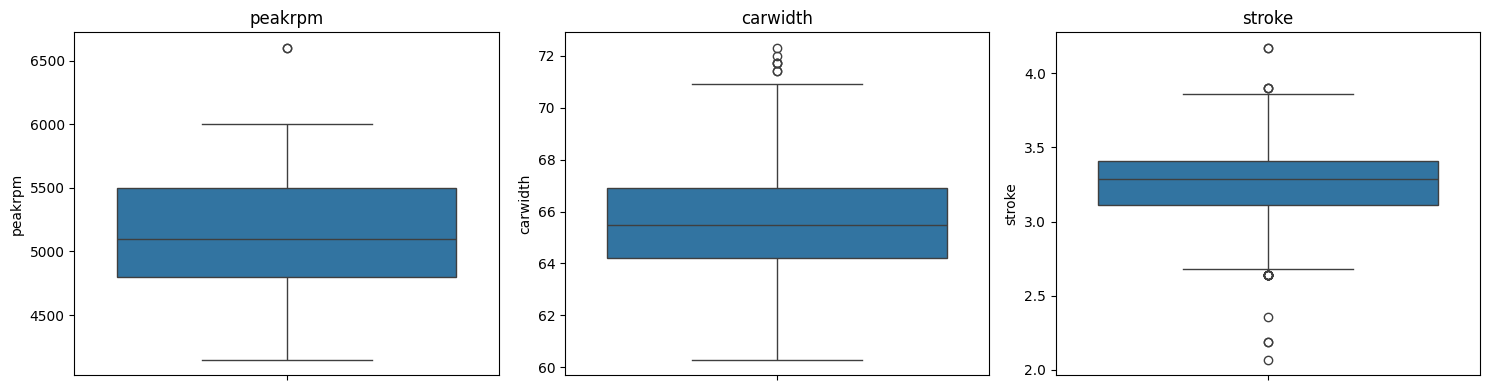

In [14]:
# Sayısal özelliklerin dağılımlarını incele
features = ["peakrpm", "carwidth", "stroke"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(features):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [ ]:
# SENİN KODUN BURAYA

### `curbweight`

<details>
    <summary>💡 <i>İpucu</i> </summary>
    <br>
    ℹ️ <code>curbweight</code> normal bir dağılıma sahiptir ve aykırı değer (outlier) içermez. Bu nedenle Standard Scaler ile ölçeklenebilir.
</details>

In [18]:
from sklearn.preprocessing import RobustScaler, StandardScaler

# RobustScaler uygulanacak sütunlar
robust_features = ["peakrpm", "stroke", "carwidth"]

# StandardScaler uygulanacak sütun
standard_features = ["curbweight"]

# RobustScaler
robust_scaler = RobustScaler()

df[robust_features] = robust_scaler.fit_transform(
    df[robust_features]
)

# StandardScaler
standard_scaler = StandardScaler()

df[standard_features] = standard_scaler.fit_transform(
    df[standard_features]
)

# Sonuçları kontrol et
print("carwidth medyan:", df["carwidth"].median())
print("curbweight maksimum:", df["curbweight"].max())

carwidth medyan: 0.0
curbweight maksimum: 2.846966340795461


In [16]:
# Ölçeklendirme sonrası kontrol
print(df[["peakrpm", "carwidth", "stroke"]].describe())

# Eksik değer kontrolü
print(df[["peakrpm", "carwidth", "stroke"]].isnull().sum())

          peakrpm      carwidth      stroke
count  191.000000  1.910000e+02  191.000000
mean     0.018699  7.298409e-15   -0.101309
std      0.674113  1.002628e+00    1.059986
min     -1.357143 -2.707719e+00   -4.066667
25%     -0.428571 -8.423904e-01   -0.600000
50%      0.000000 -2.206141e-01    0.000000
75%      0.571429  4.489911e-01    0.400000
max      2.142857  3.031754e+00    2.933333
peakrpm     0
carwidth    0
stroke      0
dtype: int64


🧪 **Kodunu test et**

In [19]:
from nbresult import ChallengeResult

result = ChallengeResult('scaling',
                         dataset = df
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/turke/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/turke/code/S16D2-S-Data-car-prices/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 4 items

test_scaling.py::TestScaling::test_carwidth PASSED                       [ 25%]
test_scaling.py::TestScaling::test_curbweight PASSED                     [ 50%]
test_scaling.py::TestScaling::test_peakrpm PASSED                        [ 75%]
test_scaling.py::TestScaling::test_stroke PASSED                         [100%]

============================== 4 passed in 0.34s ===============================


💯 You can commit your code:

git add tests/scaling.pickle

git commit -m 'Completed scaling step'

git push origin master



## (4) Kategorik özelliklerin kodlanması (Encoding the categorical features)

❓ **Soru: Kategorik değişkenlerin encode edilmesi** ❓

👇 Encode edilmesi gereken feature’ları inceleyin ve duruma göre aşağıdaki teknikleri uygulayın:

- One-hot encoding
- Manuel ordinal encoding

DataFrame içinde, orijinal feature’ları encode edilmiş versiyonlarıyla değiştirin.

### `aspiration` & `enginelocation`

<details>
    <summary>💡 <i>İpucu</i> </summary>
    <br>
    ℹ️ <code>aspiration</code> ve <code>enginelocation</code> ikili (binary) kategorik feature’lardır.
</details>

In [20]:
# One-hot encoding
df = pd.get_dummies(
    df,
    columns=["aspiration", "enginelocation"],
    drop_first=True,
    dtype=int
)

# Yeni sütunları kontrol et
print(df.filter(regex="aspiration|enginelocation").head())
print("Veri setinin boyutu:", df.shape)

   aspiration_turbo  enginelocation_rear
0                 0                    0
2                 0                    0
3                 0                    0
4                 0                    0
5                 0                    0
Veri setinin boyutu: (191, 9)


In [21]:
print("Veri setinin boyutu:", df.shape)
print("Sütunlar:", df.columns.tolist())
print("İlk 5 satır:")
display(df.head())

Veri setinin boyutu: (191, 9)
Sütunlar: ['carwidth', 'curbweight', 'enginetype', 'cylindernumber', 'stroke', 'peakrpm', 'price', 'aspiration_turbo', 'enginelocation_rear']
İlk 5 satır:


,carwidth,curbweight,enginetype,cylindernumber,stroke,peakrpm,price,aspiration_turbo,enginelocation_rear
0,-0.518519,-0.048068,dohc,four,-2.033333,-0.142857,expensive,0,0
2,0.000000,0.476395,ohcv,six,0.600000,-0.142857,expensive,0,0
3,0.000000,-0.450474,ohc,four,0.366667,0.571429,expensive,0,0
4,0.333333,0.478302,ohc,five,0.366667,0.571429,expensive,0,0
5,0.296296,-0.126260,ohc,five,0.366667,0.571429,expensive,0,0


### `enginetype`

<details>
    <summary>💡 <i>İpucu</i> </summary>
    <br>
    ℹ️ <code>enginetype</code> çok kategorili (multicategorical) bir feature’dır ve One-hot encoding uygulanmalıdır.
</details>

In [22]:
# Motor tiplerini kontrol et
print(df["enginetype"].value_counts())

# One-Hot Encoding uygula
df = pd.get_dummies(
    df,
    columns=["enginetype"],
    dtype=int
)

# Sonuçları kontrol et
print("Yeni veri seti boyutu:", df.shape)
print(df.filter(like="enginetype").head())

enginetype
ohc      138
ohcf      14
ohcv      13
dohc      11
l         11
rotor      3
dohcv      1
Name: count, dtype: int64
Yeni veri seti boyutu: (191, 15)
   enginetype_dohc  enginetype_dohcv  enginetype_l  enginetype_ohc  \
0                1                 0             0               0   
2                0                 0             0               0   
3                0                 0             0               1   
4                0                 0             0               1   
5                0                 0             0               1   

   enginetype_ohcf  enginetype_ohcv  enginetype_rotor  
0                0                0                 0  
2                0                1                 0  
3                0                0                 0  
4                0                0                 0  
5                0                0                 0  


In [23]:
df.shape

(191, 15)

### `cylindernumber`

<details>
    <summary>💡 İpucu </summary>

ℹ️ <code>cylindernumber</code> sıralı (ordinal) bir feature’dır ve sayısal değerlere manuel olarak encode edilmelidir.

</details>

In [24]:
# Silindir sayılarını sayısal değerlere dönüştür
cylinder_mapping = {
    "two": 2,
    "three": 3,
    "four": 4,
    "five": 5,
    "six": 6,
    "eight": 8,
    "twelve": 12
}

df["cylindernumber"] = df["cylindernumber"].map(cylinder_mapping)

# Kontrol et
print(df["cylindernumber"].value_counts())
print("Eksik değer:", df["cylindernumber"].isnull().sum())

cylindernumber
4     147
6      23
5      11
8       5
2       3
3       1
12      1
Name: count, dtype: int64
Eksik değer: 0


❓ Artık `cylindernumber`’ı 2 ile 12 arasında sayısal bir feature’a dönüştürdüğünüze göre, bunu ölçeklendirmeniz gerekiyor ❓

<br/>

<details>
    <summary>💡 İpucu </summary>

`cylindernumber`’ın mevcut dağılımına bakın ve kendinize şu soruları sorun:
- Ölçekleme, bir feature’ın dağılımını etkiler mi?
- Bu feature’ın dağılımına göre en uygun ölçekleme yöntemi hangisidir?
</details>

In [25]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

df["cylindernumber"] = scaler.fit_transform(
    df[["cylindernumber"]]
).ravel()

print(df["cylindernumber"].describe())

count    191.000000
mean       0.408377
std        1.095797
min       -2.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        8.000000
Name: cylindernumber, dtype: float64


<details>
<summary><i>Ölçekleme ve encoding işlemlerinden sonra DataFrame’inizin nasıl görünmesi gerektiğine dair bir ekran görüntüsü aşağıdadır</i></summary>
    
    
<img src="https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/02-Prepare-the-dataset/car_price_after_scaling_and_encoding.png">    

</details>

### `price`

👇 Hedef `price`ı kodlayın.

<details>
    <summary>💡 İpucu </summary>
    <br>
    ℹ️ <code>price</code> target değişkendir ve LabelEncoder ile encode edilmelidir.
</details>

In [26]:
# Price değişkenini sayısal değerlere dönüştür
df["price"] = df["price"].map({
    "cheap": 0,
    "expensive": 1
})

# Sonuçları kontrol et
print(df["price"].value_counts())
print("Eksik değer sayısı:", df["price"].isnull().sum())
print("Veri setinin boyutu:", df.shape)

price
1    97
0    94
Name: count, dtype: int64
Eksik değer sayısı: 0
Veri setinin boyutu: (191, 15)


🧪 **Kodunu test et**

In [28]:
# Sütun isimlerini testlerin beklediği şekilde düzelt
df = df.rename(columns={
    "aspiration_turbo": "aspiration",
    "enginelocation_rear": "enginelocation"
})

# Kontrol et
print(df[["aspiration", "enginelocation"]].head())

print("aspiration max:", df["aspiration"].max())
print("enginelocation max:", df["enginelocation"].max())

   aspiration  enginelocation
0           0               0
2           0               0
3           0               0
4           0               0
5           0               0
aspiration max: 1
enginelocation max: 1


In [29]:
from nbresult import ChallengeResult

result = ChallengeResult('encoding',
                         dataset = df)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/turke/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/turke/code/S16D2-S-Data-car-prices/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 4 items

test_encoding.py::TestEncoding::test_aspiration PASSED                   [ 25%]
test_encoding.py::TestEncoding::test_enginelocation PASSED               [ 50%]
test_encoding.py::TestEncoding::test_enginetype PASSED                   [ 75%]
test_encoding.py::TestEncoding::test_price PASSED                        [100%]

============================== 4 passed in 0.36s ===============================


💯 You can commit your code:

git add tests/encoding.pickle

git commit -m 'Completed encoding step'

git push origin master



## (5) Temel Modelleme (Base Modelling)

👏 Veri kümesi ön işleme tabi tutuldu ve artık modele uyarlanmaya hazır. 

❓ **Soru: Bir classification modelini ilk kez değerlendirme** ❓

Ön işlenmiş bu dataset üzerinde bir `LogisticRegression` modeli için cross-validation çalıştırın ve elde edilen skoru `base_model_score` adlı değişkende saklayın.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Bağımsız ve hedef değişkenleri ayır
X = df.drop(columns=["price"])
y = df["price"]

# Logistic Regression modelini oluştur
model = LogisticRegression(max_iter=1000)

# 5 katlı çapraz doğrulama
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

# Ortalama doğruluk skorunu kaydet
base_model_score = cv_scores.mean()

print("CV Skorları:", cv_scores)
print("Base Model Accuracy:", base_model_score)

CV Skorları: [0.82051282 0.81578947 0.92105263 0.78947368 0.86842105]
Base Model Accuracy: 0.8430499325236166


🧪 **Kodunu test et**

In [31]:
from nbresult import ChallengeResult

result = ChallengeResult('base_model',
                         score = base_model_score
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/turke/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/turke/code/S16D2-S-Data-car-prices/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 1 item

test_base_model.py::TestBase_model::test_base_model_score PASSED         [100%]

============================== 1 passed in 0.11s ===============================


💯 You can commit your code:

git add tests/base_model.pickle

git commit -m 'Completed base_model step'

git push origin master



## (6) Özellik Seçimi  (Feature Selection (with _Permutation Importance_))

👩🏻‍🏫 Bir feature’ın target’ı tahmin etmede gerçekten önemli olup olmadığını tespit etmenin güçlü bir yolu şudur:

1. Bir model çalıştırın ve skorunu ölçün  
2. Bu feature’ı karıştırın (shuffle edin), modeli tekrar çalıştırın ve skoru tekrar ölçün  
    - Eğer performans **belirgin şekilde düşerse**, bu feature önemlidir ve **çıkarılmamalıdır**
    - Eğer performans **çok fazla düşmezse**, bu feature **elenebilir**

❓ **Sorular** ❓

1. Modele en az bilgi katkısı sağlayan feature’ları tespit etmek için feature permutation uygulayın.
2. Model performansının belirgin şekilde düşmeye başladığını fark edene kadar zayıf feature’ları dataset’ten çıkarın.
3. Elde ettiğiniz yeni güçlü feature set’i ile yeni bir modeli cross-validation ile değerlendirin ve skorunu `strong_model_score` adlı değişkende saklayın.

In [32]:
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Modeli oluştur ve eğit
model = LogisticRegression(max_iter=1000)
model.fit(X, y)

# Permutation Importance hesapla
perm = permutation_importance(
    model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

# Özelliklerin önem skorlarını sırala
feature_importance = pd.Series(
    perm.importances_mean,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance)

curbweight          0.290576
carwidth            0.114660
stroke              0.029843
enginetype_ohcf     0.017277
enginetype_ohc      0.015183
peakrpm             0.014136
enginetype_rotor    0.011518
cylindernumber      0.009948
aspiration          0.009424
enginetype_dohc     0.005236
enginetype_ohcv     0.000524
enginelocation      0.000000
enginetype_dohcv    0.000000
enginetype_l        0.000000
dtype: float64


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import pandas as pd

# Özellikleri önem sırasına göre sırala
ranked_features = feature_importance.index.tolist()

results = []

# Farklı özellik sayılarını dene
for n in range(1, len(ranked_features) + 1):

    selected = ranked_features[:n]
    X_selected = X[selected]

    model = LogisticRegression(max_iter=2000)

    scores = cross_val_score(
        model,
        X_selected,
        y,
        cv=5,
        scoring="accuracy"
    )

    results.append({
        "n_features": n,
        "features": selected.copy(),
        "accuracy": scores.mean()
    })

# Sonuçları sırala
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="accuracy",
    ascending=False
)

# En iyi kombinasyon
best_result = results_df.iloc[0]

selected_features = best_result["features"]
strong_model_score = float(best_result["accuracy"])

print("Seçilen özellikler:", selected_features)
print("Base Model Accuracy:", base_model_score)
print("Strong Model Accuracy:", strong_model_score)

display(results_df[["n_features", "accuracy"]])

Seçilen özellikler: ['curbweight', 'carwidth']
Base Model Accuracy: 0.8430499325236166
Strong Model Accuracy: 0.9059379217273953


,n_features,accuracy
1,2,0.905938
0,1,0.890283
2,3,0.879622
5,6,0.874494
6,7,0.874494
3,4,0.874359
4,5,0.869096
7,8,0.863968
8,9,0.848178
9,10,0.848178


🧪 **Kodunu test et**

In [37]:
from nbresult import ChallengeResult

result = ChallengeResult('strong_model',
                         score = strong_model_score
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/turke/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/turke/code/S16D2-S-Data-car-prices/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 1 item

test_strong_model.py::TestStrong_model::test_strong_model_score PASSED   [100%]

============================== 1 passed in 0.01s ===============================


💯 You can commit your code:

git add tests/strong_model.pickle

git commit -m 'Completed strong_model step'

git push origin master



## Bonus -  Verilerinizi sınıflandırma (Stratifying your data) ⚖️

💡 Veriyi training ve testing olarak bölerken, dataset’imizdeki kategorik değişkenlerin oranına dikkat etmemiz gerekir — ister target `y`’nin sınıfları olsun ister `X` içindeki kategorik bir feature olsun.

Aşağıda bir örneğe bakalım 👇

❓ Orijinal `X` ve `y` verinizi sklearn’in `train_test_split` fonksiyonunu kullanarak training ve testing olarak ayırın; karşılaştırılabilir sonuçlar elde etmek için `random_state=1` ve `test_size=0.3` kullanın.

In [38]:
from sklearn.model_selection import train_test_split

# Orijinal X ve y verilerini ayır
X = df.drop(columns=["price"])
y = df["price"]

# Eğitim ve test setlerini oluştur
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=1
)

print("Eğitim veri boyutu:", X_train.shape)
print("Test veri boyutu:", X_test.shape)

Eğitim veri boyutu: (133, 14)
Test veri boyutu: (58, 14)


❓ Training dataset’inizde ve testing dataset’inizde `price` sınıfı **1** olan araçların oranını kontrol edin.

> _Ham `df` içinde bu orana baktığınızda, yaklaşık **%50 / %50** olması gerekir._

In [39]:
print("Orijinal veri - Pahalı araba oranı:", y.mean())
print("Eğitim seti - Pahalı araba oranı:", y_train.mean())
print("Test seti - Pahalı araba oranı:", y_test.mean())



Orijinal veri - Pahalı araba oranı: 0.5078534031413613
Eğitim seti - Pahalı araba oranı: 0.5037593984962406
Test seti - Pahalı araba oranı: 0.5172413793103449


☝️ Hâlâ yaklaşık olarak **%50 / %50** civarında olmalı.

***Peki random state’i değiştirirsek ne olur?***

❓ `random_state` değerlerini **1’den 10’a** kadar döngüye alın ve her seferinde training ve testing dataset’lerindeki `price` sınıfı **1** olan araçların oranını hesaplayın. ❓

In [40]:
from sklearn.model_selection import train_test_split

for i in range(1, 11):
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3,
        random_state=i
    )

    print(f"random_state = {i}")
    print(f"Train pahalı araba oranı: {y_train.mean():.2%}")
    print(f"Test pahalı araba oranı: {y_test.mean():.2%}")
    print("-" * 40)

random_state = 1
Train pahalı araba oranı: 50.38%
Test pahalı araba oranı: 51.72%
----------------------------------------
random_state = 2
Train pahalı araba oranı: 48.12%
Test pahalı araba oranı: 56.90%
----------------------------------------
random_state = 3
Train pahalı araba oranı: 50.38%
Test pahalı araba oranı: 51.72%
----------------------------------------
random_state = 4
Train pahalı araba oranı: 53.38%
Test pahalı araba oranı: 44.83%
----------------------------------------
random_state = 5
Train pahalı araba oranı: 53.38%
Test pahalı araba oranı: 44.83%
----------------------------------------
random_state = 6
Train pahalı araba oranı: 49.62%
Test pahalı araba oranı: 53.45%
----------------------------------------
random_state = 7
Train pahalı araba oranı: 53.38%
Test pahalı araba oranı: 44.83%
----------------------------------------
random_state = 8
Train pahalı araba oranı: 48.87%
Test pahalı araba oranı: 55.17%
----------------------------------------
random_state = 9

Her seferinde oranların değiştiğini, hatta bazen oldukça ciddi şekilde değiştiğini gözlemleyeceksiniz 😱! Bu durum model performansını etkileyebilir.

❓ `train_test_split(random_state=1)` kullanılarak eğitilen bir Logistic Regression modelinin test skorunu,  
`random_state=9` kullanılarak eğitilen modelin test skoru ile karşılaştırın ❓

Eğitimi training data üzerinde yapmayı ve skoru testing data üzerinde hesaplamayı unutmayın.

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# İki farklı random_state değerini karşılaştır
for state in [1, 9]:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3,
        random_state=state
    )

    # Modeli oluştur
    model = LogisticRegression(max_iter=2000)

    # Eğitim verisiyle eğit
    model.fit(X_train, y_train)

    # Test verisiyle değerlendir
    score = model.score(X_test, y_test)

    print(f"Random State: {state}")
    print(f"Test Accuracy: {score:.4f}")
    print(f"Train sınıf 1 oranı: {y_train.mean():.2%}")
    print(f"Test sınıf 1 oranı: {y_test.mean():.2%}")
    print("-" * 40)

Random State: 1
Test Accuracy: 0.9310
Train sınıf 1 oranı: 50.38%
Test sınıf 1 oranı: 51.72%
----------------------------------------
Random State: 9
Test Accuracy: 0.7931
Train sınıf 1 oranı: 57.89%
Test sınıf 1 oranı: 34.48%
----------------------------------------


👀 `random_state=9` ile çok daha düşük bir skor görmelisiniz; çünkü bu test setindeki sınıf **1** araçların oranı %34.5 iken, training setinde bu oran %57.9’a, hatta orijinal dataset’te yaklaşık %50’ye yakındır.

Bu durum oldukça önemlidir; çünkü dataset’te oluşan bu **rastlantısal dengesizlik**, yalnızca model performansını düşürmekle kalmaz, aynı zamanda eğitim veya değerlendirme sırasında “gerçekliği” de bozabilir 🧐

***Peki bu sorunu nasıl çözebiliriz? Tren seti ve test seti arasında sınıfların dağılımını nasıl aynı tutabiliriz? 🔧***

🎁 Neyse ki sklearn’de, estimator (yani model) bir classifier olduğunda ve target bir sınıf olduğunda, bu durum `cross_validate` tarafından otomatik olarak ele alınır. 📚 [**sklearn.model_selection.cross_validate**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) dokümantasyonunda `cv` parametresini inceleyin.

Çözüm, aşağıdakini kullanmaktır:

> 📚 [**Stratification (Katmanlama)**](https://scikit-learn.org/stable/modules/cross_validation.html#stratification)

### Hedefin tabakalaşması (Stratification of the target)

💡 ***Stratification*** tekniğini `train_test_split` içinde de kullanabiliriz.

❓ Bu kez **1’den 10’a** kadar olan `random_state` döngüsünü tekrar çalıştırın, ancak bu sefer holdout yöntemine ***`stratify=y`*** parametresini de ekleyin. ❓

In [42]:
from sklearn.model_selection import train_test_split

# random_state değerlerini 1'den 10'a kadar dene
for state in range(1, 11):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.3,
        random_state=state,
        stratify=y
    )

    print(f"Random State: {state}")
    print(f"Train sınıf 1 oranı: {y_train.mean():.2%}")
    print(f"Test sınıf 1 oranı: {y_test.mean():.2%}")
    print("-" * 40)

Random State: 1
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 2
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 3
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 4
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 5
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 6
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 7
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 8
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
----------------------------------------
Random State: 9
Train sınıf 1 oranı: 51.13%
Test sınıf 1 oranı: 50.00%
---------------------------------

👀 Random state değişse bile, training ve testing verilerindeki sınıf oranları, orijinal `y` içindeki oranlarla aynı tutulur. İşte _stratification_ (katmanlama) tam olarak budur.

`train_test_split` fonksiyonunu `stratify` parametresiyle kullandığımızda, training ve testing verileri arasında **bir feature’ın oranlarını da koruyabiliriz**. Bu, özellikle aşağıdaki durumlarda son derece önemlidir:

- Churn tahmininde erkek ve kadın müşteri oranlarını korumak 🙋‍♂️ 🙋
- Ev fiyatlarını tahmin ederken büyük ve küçük evlerin oranlarını korumak 🏠 🏰
- Bir sonraki ürünü önerirken 1–5 arası review score dağılımını (multiclass!) korumak 🛍️
- vb.

Örneğin, bizim dataset’imizde `aspiration` feature’ının training ve testing verilerinde aynı oranda kalmasını istiyorsak, şu şekilde yazabiliriz:

`train_test_split(X, y, test_size=0.3, stratify=X.aspiration)`

---

Gördüğümüz gibi, **`cross_validate` [target değişkeni otomatik olarak stratify edebilir](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html#:~:text=For%20int/None%20inputs%2C%20if%20the%20estimator%20is%20a%20classifier%20and%20y%20is%20either%20binary%20or%20multiclass%2C%20StratifiedKFold%20is%20used.)**, ancak **feature’lar için bunu yapmaz** 🤔 Bunun için biraz ekstra çalışmaya ihtiyacımız var.

Bunun için `StratifiedKFold` kullanmamız gerekiyor 🔬

### Tabakalaşma (Stratification - generalized)

📚 [**StratifiedKFold**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html), veriyi `K` parçaya bölerken belirli sütunlar (feature veya target) üzerinden stratification yapmamıza olanak tanır.

Bu sayede, ilgilendiğimiz kategorik feature’ların oranlarını koruyarak manuel bir cross-validation yapabiliriz — bunu ikili (binary) `aspiration` feature’ı ile deneyelim:

In [43]:
from sklearn.model_selection import StratifiedKFold

# Veriyi 5 fold’a bölecek bir stratified k-fold oluşturma
skf = StratifiedKFold(n_splits=5)
scores = []

# .split() metodu bir iterator oluşturur; 'X.aspiration' stratify edeceğimiz feature’dır
for train_indices, test_indices in skf.split(X, X.aspiration):

    # 'train_indices' ve 'test_indices', orantılı bölünmeler üreten indeks listeleridir
    X_train, X_test = X.iloc[train_indices], X.iloc[test_indices]
    y_train, y_test = y.iloc[train_indices], y.iloc[test_indices]

    # modeli başlatma ve eğitme
    model = LogisticRegression()
    model.fit(X_train, y_train)

    # en sonunda 5 fold’un ortalamasını almak için skoru listeye ekleme
    scores.append(model.score(X_test, y_test))

np.array(scores).mean()

0.8585695006747638

📚 [**StratifiedKFold**](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html), veriyi `K` parçaya bölerken belirli sütunlar (feature veya target) üzerinden stratification yapmamıza olanak tanır.

Bu sayede, ilgilendiğimiz kategorik feature’ların oranlarını koruyarak manuel bir cross-validation yapabiliriz — bunu ikili (binary) `aspiration` feature’ı ile deneyelim:


🏁 Tebrikler! Tüm veri setini hazırladınız, özellik seçimi yaptınız ve hatta tabakalaşma hakkında bilgi edindiniz 💪.

💾 Not defterinizi git add/commit/push yapmayı unutmayın...

🚀 ... ve bir sonraki challenge'a geçin!